# Project : Boron Implant and Anneal Diffusion Model

**What this does:** models a Boron ion implant into n-type silicon, then simulates the anneal (drive-in) by solving Fick's second law numerically. It extracts junction depth and sheet resistance for several anneal temperatures, and checks the numerical solver against the exact analytic solution.

**Tools:** Python (NumPy, SciPy, Matplotlib).

**Model assumptions:**
1. The as-implanted profile is Gaussian, set by dose Q, projected range Rp and straggle dRp.
2. Diffusion uses a constant, intrinsic diffusivity D = D0 exp(-Ea/kT). No concentration-dependent diffusion and no transient enhanced diffusion (TED).
3. No dopant loss through the surface (zero-flux boundary).
4. All boron is electrically active; hole mobility comes from a Caughey-Thomas model.
5. Parameters come from the sources in the table in section 1. Range and straggle are tabulated LSS-type values, and diffusivity is the intrinsic Arrhenius form. The hole-mobility model is the least certain input, so read sheet resistance as a trend and quote junction depth as the quantitative result.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

k_B = 8.617333e-5    # Boltzmann constant, eV/K
q   = 1.602177e-19   # electron charge, C

def integrate(y, x):
    """Trapezoid rule (written out so it works on any NumPy version)."""
    return np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x))

## 1. Inputs
Change these and re-run. Units are cm-based (cm, cm^-2, cm^-3) to match device-physics textbooks.

**Where each parameter comes from**

| Parameter | Value | Source | Status |
|---|---|---|---|
| Boron Rp, 100 keV in Si | 0.2994 um | SFU lecture table (attributed to Gibbons, Johnson and Mylroie, *Projected Range Statistics*, 2nd ed.) | Cross-checked: CityU AP6120 ch. 9 gives 0.2968 um |
| Boron straggle, 100 keV | 0.0710 um | same SFU table | Cross-checked: CityU gives 0.0735 um |
| D0, Ea (intrinsic boron diffusivity) | 0.76 cm^2/s, 3.46 eV | CityU AP6120 ch. 8 | One source only. Confirm in a textbook or your course notes |
| Hole mobility | Arora set (54.3, 407, 2.35e17, 0.88) or the alternative set below | COMSOL semiconductor docs (Arora et al. 1982) | Models disagree by 25 to 30% on sheet resistance, so use sheet resistance as a trend |
| Dose, substrate doping, anneal time | 1e14, 1e15, 30 min | Chosen by you | Design inputs, not measured data |

Other energies (SFU table, Rp / straggle in um): 40 keV = 0.1302 / 0.0443, 50 keV = 0.1608 / 0.0504, 60 keV = 0.1903 / 0.0556.

In [2]:
# ---- Implant (boron into n-type silicon) ----
Q     = 1e14       # dose, cm^-2
ENERGY_keV = 100   # implant energy (for the record; Rp and dRp below are the 100 keV values)
Rp    = 0.2994e-4  # projected range, cm (0.2994 um) -- SFU table / Gibbons et al. (40 keV: 0.1302e-4)
dRp   = 0.0710e-4  # straggle, cm (0.0710 um)        -- same table              (40 keV: 0.0443e-4)
N_sub = 1e15       # n-type substrate (phosphorus) doping, cm^-3

# ---- Boron diffusivity, intrinsic: D = D0 * exp(-Ea / kT) ----
D0 = 0.76          # cm^2/s
Ea = 3.46          # eV

def D_boron(T_C):
    T = T_C + 273.15
    return D0 * np.exp(-Ea / (k_B * T))

# ---- Anneal ----
t_anneal = 30 * 60                      # 30 minutes, in seconds
temps    = [900, 950, 1000, 1050, 1100] # deg C

# ---- Hole mobility vs total doping (300 K): mu = mu_min + (mu_max - mu_min) / (1 + (N/N_ref)^alpha) ----
# Two parameter sets. They give sheet resistances that differ by 25-30%, so treat Rs as a trend.
MOBILITY_SETS = {
    "arora":    (54.3, 54.3 + 407.0, 2.35e17, 0.88),   # Arora et al. 1982, as listed in COMSOL docs (mu_max = mu_min + mu_d)
    "set_alt":  (47.7, 495.0,        6.3e16,  0.76),   # alternative set; source not independently confirmed
}
MOBILITY = "arora"

def mu_holes(N, model=None):
    mu_min, mu_max, N_ref, alpha = MOBILITY_SETS[model or MOBILITY]
    return mu_min + (mu_max - mu_min) / (1 + (N / N_ref) ** alpha)

for T in temps:
    print(f"{T} C: D = {D_boron(T):.2e} cm^2/s, diffusion length sqrt(2Dt) = {np.sqrt(2*D_boron(T)*t_anneal)*1e4:.3f} um")

900 C: D = 1.04e-15 cm^2/s, diffusion length sqrt(2Dt) = 0.019 um
950 C: D = 4.21e-15 cm^2/s, diffusion length sqrt(2Dt) = 0.039 um
1000 C: D = 1.53e-14 cm^2/s, diffusion length sqrt(2Dt) = 0.074 um
1050 C: D = 5.03e-14 cm^2/s, diffusion length sqrt(2Dt) = 0.135 um
1100 C: D = 1.52e-13 cm^2/s, diffusion length sqrt(2Dt) = 0.234 um


## 2. Profiles: as-implanted and exact analytic solution
The implant is a Gaussian centred at Rp. A mirror-image term about the surface folds the tiny tail that would sit at x < 0 back into the silicon, so the total dose is exactly Q. With zero flux at the surface, Fick's second law with constant D then has an exact solution: each Gaussian simply widens, sigma^2 = dRp^2 + 2Dt. We use that as the reference for the numerical solver.

In [3]:
def initial_profile(x, Q, Rp, dRp):
    """As-implanted Gaussian plus mirror image (total dose = Q exactly)."""
    g = lambda x0: np.exp(-(x - x0) ** 2 / (2 * dRp ** 2))
    return Q / (np.sqrt(2 * np.pi) * dRp) * (g(Rp) + g(-Rp))

def analytic_profile(x, Q, Rp, dRp, D, t):
    """Exact solution of dC/dt = D d2C/dx2 with zero flux at x = 0."""
    s2 = dRp ** 2 + 2 * D * t
    g = lambda x0: np.exp(-(x - x0) ** 2 / (2 * s2))
    return Q / np.sqrt(2 * np.pi * s2) * (g(Rp) + g(-Rp))

## 3. Numerical solver: Crank-Nicolson
Crank-Nicolson is second-order accurate in time and unconditionally stable, so the step size is limited by accuracy, not stability. Both ends use a zero-flux (reflecting) boundary via a ghost node. Each step solves a tridiagonal system.

In [4]:
def diffuse_crank_nicolson(x, C0, D, t_total, n_steps):
    dx = x[1] - x[0]
    dt = t_total / n_steps
    r  = D * dt / dx ** 2
    n  = len(x)

    # Left-hand matrix A = I - (r/2) L in banded form for solve_banded((1,1), ...)
    ab = np.zeros((3, n))
    ab[1, :]    = 1 + r
    ab[0, 2:]   = -r / 2     # super-diagonal
    ab[2, :n-2] = -r / 2     # sub-diagonal
    ab[0, 1]    = -r         # surface row: ghost node doubles the neighbour term
    ab[2, n-2]  = -r         # far-end row: same

    C = C0.copy()
    for _ in range(n_steps):
        rhs = (1 - r) * C
        rhs[1:-1] += (r / 2) * (C[:-2] + C[2:])
        rhs[0]    += r * C[1]
        rhs[-1]   += r * C[-2]
        C = solve_banded((1, 1), ab, rhs)
    return C

## 4. Extracting junction depth and sheet resistance
- **Junction depth x_j:** the depth beyond the peak where the boron concentration falls to the substrate doping.
- **Sheet resistance:** R_s = 1 / ( q * integral from 0 to x_j of mu(N) * (C - N_sub) dx ). Here C - N_sub is the net hole density (full ionization assumed) and mobility depends on total impurity concentration.

In [5]:
def junction_depth(x, C, N_sub):
    C = np.maximum(C, 1e-30)
    ipk = np.argmax(C)
    below = np.where(C[ipk:] <= N_sub)[0]
    if len(below) == 0:
        return np.nan
    j = ipk + below[0]
    c1, c2 = np.log10(C[j - 1]), np.log10(C[j])
    f = (np.log10(N_sub) - c1) / (c2 - c1)
    return x[j - 1] + f * (x[j] - x[j - 1])

def sheet_resistance(x, C, N_sub, model=None):
    xj = junction_depth(x, C, N_sub)
    m = x <= xj
    p_net = np.maximum(C[m] - N_sub, 0)
    sigma = q * mu_holes(C[m] + N_sub, model) * p_net   # conductivity, S/cm
    return 1.0 / integrate(sigma, x[m])             # ohm/square

## 5. Run the anneal sweep and validate
Checks printed below: (1) dose conservation, (2) maximum numerical-vs-analytic error as a percentage of the peak, (3) junction depth and sheet resistance from both solutions.

In [6]:
x  = np.linspace(0, 3.0e-4, 1501)    # 0 to 3 um, 2 nm spacing (cm)
C0 = initial_profile(x, Q, Rp, dRp)
n_steps = 600
print(f"As-implanted dose: {integrate(C0, x):.4e} cm^-2 (target {Q:.1e})\n")

results = {}
for T in temps:
    D = D_boron(T)
    C_num = diffuse_crank_nicolson(x, C0, D, t_anneal, n_steps)
    C_ana = analytic_profile(x, Q, Rp, dRp, D, t_anneal)
    results[T] = dict(
        C_num=C_num, C_ana=C_ana,
        xj_num=junction_depth(x, C_num, N_sub), xj_ana=junction_depth(x, C_ana, N_sub),
        Rs_num=sheet_resistance(x, C_num, N_sub), Rs_ana=sheet_resistance(x, C_ana, N_sub),
        err=np.max(np.abs(C_num - C_ana)) / np.max(C_ana) * 100,
        dose_err=(integrate(C_num, x) - Q) / Q * 100,
    )

print(f"{'T (C)':>6} {'xj num (um)':>12} {'xj ana (um)':>12} {'Rs num':>9} {'Rs ana':>9} {'max err %':>10} {'dose err %':>11}")
for T in temps:
    r = results[T]
    print(f"{T:>6} {r['xj_num']*1e4:>12.4f} {r['xj_ana']*1e4:>12.4f} {r['Rs_num']:>9.1f} {r['Rs_ana']:>9.1f} {r['err']:>10.4f} {r['dose_err']:>11.2e}")

print(f"\nSheet resistance (ohm/sq) with each mobility set; default is '{MOBILITY}'")
print(f"{'T (C)':>6} " + " ".join(f"{k:>10}" for k in MOBILITY_SETS) + f" {'difference':>11}")
for T in temps:
    vals = [sheet_resistance(x, results[T]['C_num'], N_sub, k) for k in MOBILITY_SETS]
    print(f"{T:>6} " + " ".join(f"{v:>10.1f}" for v in vals) + f" {abs(vals[0]-vals[1])/max(vals)*100:>10.1f}%")
print("The two models disagree strongly, so quote junction depth numerically and sheet resistance as a trend.")

As-implanted dose: 1.0000e+14 cm^-2 (target 1.0e+14)

 T (C)  xj num (um)  xj ana (um)    Rs num    Rs ana  max err %  dose err %
   900       0.6046       0.6046     649.7     649.7     0.0006   -9.98e-12
   950       0.6333       0.6333     630.2     630.2     0.0018    7.98e-12
  1000       0.7169       0.7169     583.8     583.8     0.0025   -2.00e-12
  1050       0.9033       0.9033     525.5     525.5     0.0017    4.48e-11
  1100       1.2397       1.2397     473.6     473.6     0.0008   -8.89e-12

Sheet resistance (ohm/sq) with each mobility set; default is 'arora'
 T (C)      arora    set_alt  difference
   900      649.7      864.3       24.8%
   950      630.2      845.2       25.4%
  1000      583.8      800.1       27.0%
  1050      525.5      741.1       29.1%
  1100      473.6      681.9       30.6%
The two models disagree strongly, so quote junction depth numerically and sheet resistance as a trend.


## 6. Plots
Solid lines are the numerical solution and open circles the analytic one. Temperature uses a single-hue ramp (light = cooler, dark = hotter).

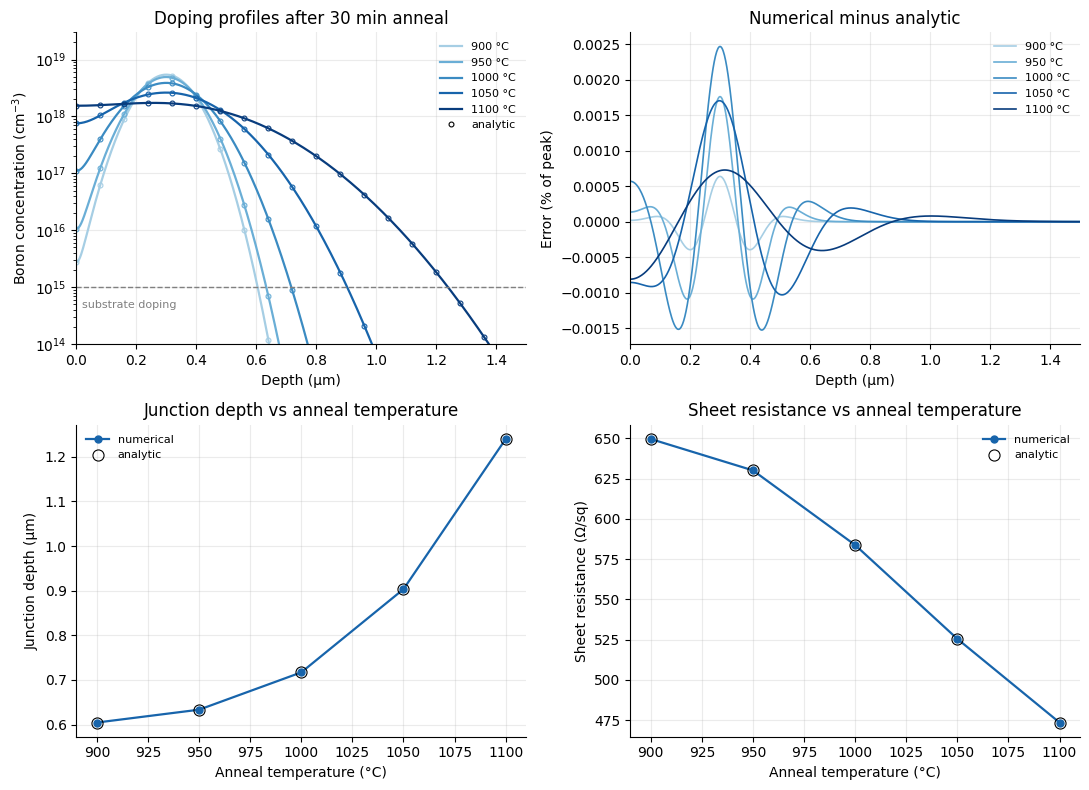

In [7]:
import matplotlib.cm as cm
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
cols = {T: cm.Blues(0.35 + 0.6 * i / (len(temps) - 1)) for i, T in enumerate(temps)}
xu = x * 1e4   # um for plotting

fig, axs = plt.subplots(2, 2, figsize=(11, 8))

ax = axs[0, 0]
for T in temps:
    ax.semilogy(xu, np.maximum(results[T]["C_num"], 1e-10), color=cols[T], lw=1.6, label=f"{T} °C")
    ax.semilogy(xu[::40], results[T]["C_ana"][::40], "o", ms=3.5, mfc="none", mec=cols[T], mew=0.8)
ax.axhline(N_sub, color="gray", ls="--", lw=1)
ax.text(0.02, N_sub * 0.6, "substrate doping", ha="left", va="top", color="gray", fontsize=8)
ax.plot([], [], "o", ms=3.5, mfc="none", mec="k", mew=0.8, label="analytic")
ax.set_ylim(1e14, 3e19); ax.set_xlim(0, 1.5)
ax.set_xlabel("Depth (µm)"); ax.set_ylabel("Boron concentration (cm$^{-3}$)")
ax.set_title("Doping profiles after 30 min anneal"); ax.legend(fontsize=8, frameon=False)

ax = axs[0, 1]
for T in temps:
    err = (results[T]["C_num"] - results[T]["C_ana"]) / np.max(results[T]["C_ana"]) * 100
    ax.plot(xu, err, color=cols[T], lw=1.2, label=f"{T} °C")
ax.set_xlim(0, 1.5); ax.set_xlabel("Depth (µm)"); ax.set_ylabel("Error (% of peak)")
ax.set_title("Numerical minus analytic"); ax.legend(fontsize=8, frameon=False)

ax = axs[1, 0]
ax.plot(temps, [results[T]["xj_num"] * 1e4 for T in temps], "-o", color=cm.Blues(0.8), lw=1.6, ms=5, label="numerical")
ax.plot(temps, [results[T]["xj_ana"] * 1e4 for T in temps], "o", ms=8, mfc="none", mec="k", mew=0.8, label="analytic")
ax.set_xlabel("Anneal temperature (°C)"); ax.set_ylabel("Junction depth (µm)")
ax.set_title("Junction depth vs anneal temperature"); ax.legend(fontsize=8, frameon=False)

ax = axs[1, 1]
ax.plot(temps, [results[T]["Rs_num"] for T in temps], "-o", color=cm.Blues(0.8), lw=1.6, ms=5, label="numerical")
ax.plot(temps, [results[T]["Rs_ana"] for T in temps], "o", ms=8, mfc="none", mec="k", mew=0.8, label="analytic")
ax.set_xlabel("Anneal temperature (°C)"); ax.set_ylabel("Sheet resistance (Ω/sq)")
ax.set_title("Sheet resistance vs anneal temperature"); ax.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig("fig_implant_diffusion.png", dpi=150)
plt.show()

## 7. Convergence study (grid spacing and time step)

The grid spacing and time step are refined together at 1000 °C. Junction depth and sheet resistance are compared against the analytic solution at each refinement. The errors shrink as the mesh is refined, which shows the numerical solution has converged.

In [8]:
def run_case(T, nx, ns):
    xg  = np.linspace(0, 3.0e-4, nx)
    C0g = initial_profile(xg, Q, Rp, dRp)
    C   = diffuse_crank_nicolson(xg, C0g, D_boron(T), t_anneal, ns)
    return junction_depth(xg, C, N_sub), sheet_resistance(xg, C, N_sub)

T_test = 1000
xj_ref = results[T_test]["xj_ana"]; Rs_ref = results[T_test]["Rs_ana"]
print(f"Convergence at {T_test} C (reference = analytic: xj = {xj_ref*1e4:.5f} um, Rs = {Rs_ref:.3f} ohm/sq)")
print(f"{'grid pts':>9} {'dx (nm)':>8} {'steps':>6} {'xj (um)':>10} {'Rs':>9} {'xj err %':>9} {'Rs err %':>9}")
for nx, ns in [(751, 150), (1501, 300), (3001, 600), (6001, 1200)]:
    xj, Rs = run_case(T_test, nx, ns)
    dx_nm = 3.0e-4 / (nx - 1) * 1e7
    print(f"{nx:>9} {dx_nm:>8.2f} {ns:>6} {xj*1e4:>10.5f} {Rs:>9.3f} {(xj-xj_ref)/xj_ref*100:>9.4f} {(Rs-Rs_ref)/Rs_ref*100:>9.4f}")

Convergence at 1000 C (reference = analytic: xj = 0.71690 um, Rs = 583.816 ohm/sq)
 grid pts  dx (nm)  steps    xj (um)        Rs  xj err %  Rs err %
      751     4.00    150    0.71704   583.810    0.0205   -0.0010
     1501     2.00    300    0.71693   583.815    0.0052   -0.0003
     3001     1.00    600    0.71691   583.816    0.0015   -0.0001
     6001     0.50   1200    0.71690   583.816    0.0005   -0.0000
